In [11]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import joblib

In [12]:
dataset = pd.read_csv(r"C:\Users\mateus_s_cavalheiro\Documents\GitHub\AeroMotion-Dynamics\data\processed\dados_sensores_aeromotion_tratado.csv")
dataset['timestamp'] = pd.to_datetime(dataset['timestamp'])
dataset = dataset.sort_values(by=['id_equipamento', 'timestamp']).reset_index(drop=True)
dataset.head()

,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha,temp_rolling_mean_1h,temp_rolling_std_1h,temp_rolling_mean_6h,temp_rolling_std_6h,vib_rolling_mean_1h,vib_rolling_std_1h,vib_rolling_mean_6h,vib_rolling_std_6h,severidade_dinamica
0,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,2.500,3.51,2382.7,44.97,18.73,0,57.830000,0.000000,57.830000,0.000000,2.500000,0.000000,2.500000,0.000000,0.001049
1,2026-01-01 01:00:00,TURB-101,Carga_Media,101.4,58.03,2.500,4.00,2925.2,52.83,27.75,0,57.930000,0.141421,57.930000,0.141421,2.500000,0.000000,2.500000,0.000000,0.000855
2,2026-01-01 01:10:00,TURB-101,Carga_Alta,101.5,75.77,7.985,4.68,3569.7,63.52,37.74,0,63.876667,10.300414,63.876667,10.300414,4.328333,3.166766,4.328333,3.166766,0.002237
3,2026-01-01 02:30:00,TURB-101,Carga_Media,106.4,64.11,13.470,4.19,3011.2,49.74,42.56,2,63.935000,8.411062,63.935000,8.411062,6.613750,5.251488,6.613750,5.251488,0.004473
4,2026-01-01 03:30:00,TURB-101,Cruzeiro,109.2,49.55,1.280,4.08,2477.4,44.98,18.99,0,61.058000,9.718288,61.058000,9.718288,5.547000,5.135501,5.547000,5.135501,0.000517


In [13]:
colunas_interesse = [
    'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar',
    'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp',
    'severidade_dinamica', 'temp_rolling_mean_1h', 'vib_rolling_mean_1h', 'tipo_falha'
]
matriz_corr = dataset[colunas_interesse].corr()
print("--- Matriz de Correlação Linear ---")
print(matriz_corr.round(3))

--- Matriz de Correlação Linear ---
                       temperatura_mancal_c  vibracao_rms_mms  \
temperatura_mancal_c                  1.000             0.191   
vibracao_rms_mms                      0.191             1.000   
pressao_oleo_bar                      0.016             0.221   
rotacao_rpm                           0.682             0.308   
emissao_acustica_db                   0.447             0.594   
corrente_eletrica_amp                 0.592             0.548   
severidade_dinamica                   0.062             0.973   
temp_rolling_mean_1h                  0.410             0.068   
vib_rolling_mean_1h                   0.082             0.408   
tipo_falha                            0.446             0.540   

                       pressao_oleo_bar  rotacao_rpm  emissao_acustica_db  \
temperatura_mancal_c              0.016        0.682                0.447   
vibracao_rms_mms                  0.221        0.308                0.594   
pressao_oleo_bar 

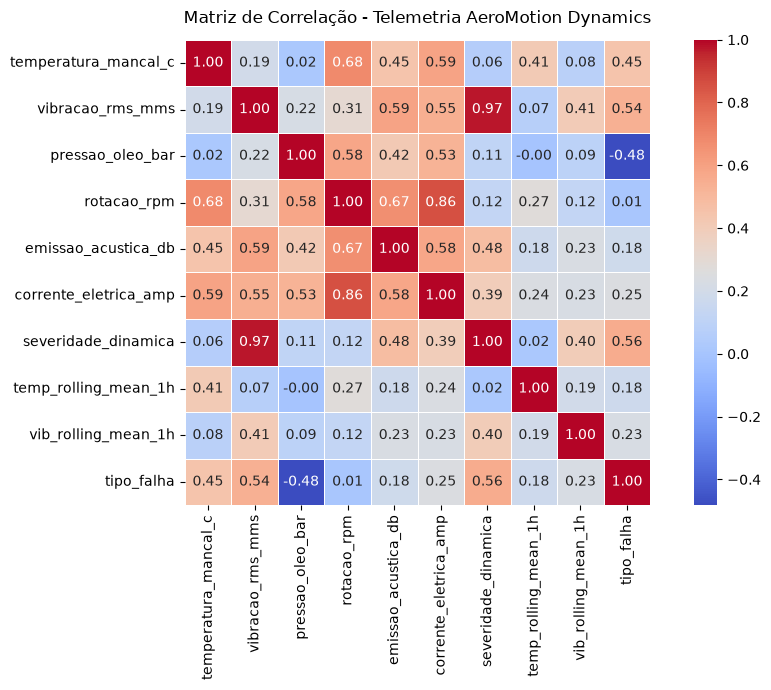

In [14]:
plt.figure(figsize=(10, 7))
sb.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=0.5)
plt.title('Matriz de Correlação - Telemetria AeroMotion Dynamics', fontsize=12, pad=12)
plt.tight_layout()
plt.show()

In [15]:
# Lista de features preditivas do processo industrial
features = [
    'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms',
    'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp',
    'temp_rolling_mean_1h', 'temp_rolling_std_1h', 'temp_rolling_mean_6h', 'temp_rolling_std_6h',
    'vib_rolling_mean_1h', 'vib_rolling_std_1h', 'vib_rolling_mean_6h', 'vib_rolling_std_6h',
    'severidade_dinamica'
]

# Ordenação cronológica estrita antes da partição para evitar data leakage
dataset_temporal = dataset.sort_values(by='timestamp').reset_index(drop=True)
X = dataset_temporal[features]
y = dataset_temporal['tipo_falha']

split_point = int(len(dataset_temporal) * 0.70)
X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

print(f"Amostras para Treino (70%): {X_train.shape[0]}")
print(f"Amostras para Teste (30%): {X_test.shape[0]}")

Amostras para Treino (70%): 8400
Amostras para Teste (30%): 3600


In [16]:
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Random Forest com pesos balanceados para mitigar o desbalanceamento (~12% falhas)
model_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
model_gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

model_rf.fit(X_train, y_train)
model_gb.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [17]:
# Treinado exclusivamente com dados de operação normal (classe 0)
X_train_normal = X_train[y_train == 0]
model_iso = IsolationForest(contamination=0.01, random_state=42)
model_iso.fit(X_train_normal)

# Inferências no teste
prediction_rf = model_rf.predict(X_test)
prediction_gb = model_gb.predict(X_test)
prediction_iso = model_iso.predict(X_test)  # -1 indica anomalia física

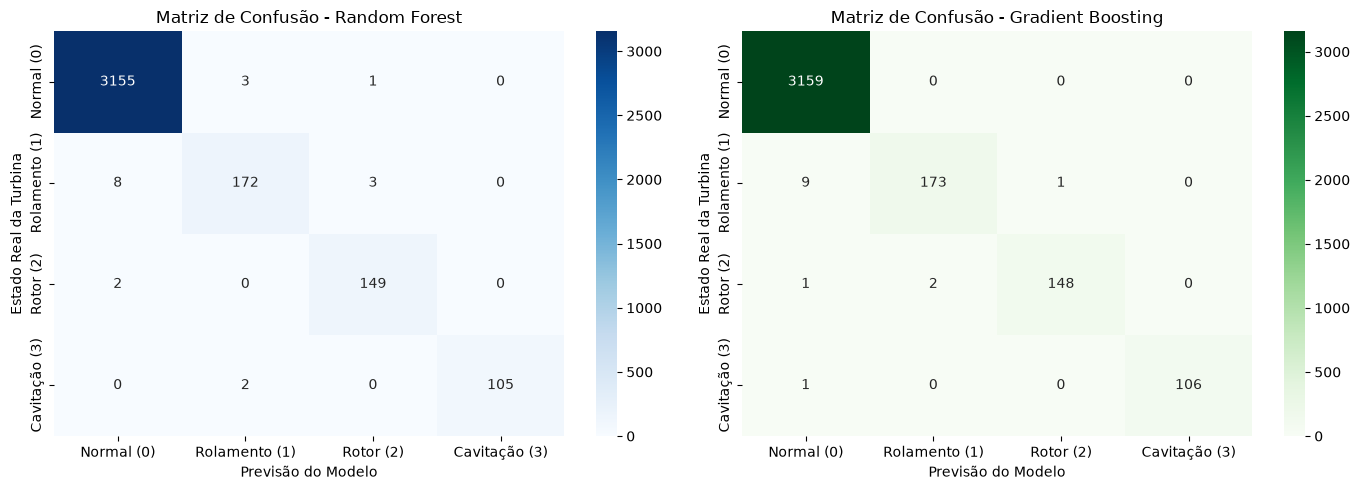


--- Tabela Comparativa de Métricas ---


,Modelo,Acurácia,Precisão,Recall,F1-Score
0,Random Forest,99.47%,98.56%,97.67%,98.10%
1,Gradient Boosting,99.61%,99.46%,97.90%,98.67%


In [18]:
classes_nomes = ['Normal (0)', 'Rolamento (1)', 'Rotor (2)', 'Cavitação (3)']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_rf = confusion_matrix(y_test, prediction_rf)
sb.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0],
           xticklabels=classes_nomes, yticklabels=classes_nomes)
axes[0].set_title('Matriz de Confusão - Random Forest')
axes[0].set_xlabel('Previsão do Modelo')
axes[0].set_ylabel('Estado Real da Turbina')

cm_gb = confusion_matrix(y_test, prediction_gb)
sb.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
           xticklabels=classes_nomes, yticklabels=classes_nomes)
axes[1].set_title('Matriz de Confusão - Gradient Boosting')
axes[1].set_xlabel('Previsão do Modelo')
axes[1].set_ylabel('Estado Real da Turbina')

plt.tight_layout()
plt.show()

def calcular_metricas(y_real, y_pred, modelo_nome):
    return {
        'Modelo': modelo_nome,
        'Acurácia': f"{accuracy_score(y_real, y_pred):.2%}",
        'Precisão': f"{precision_score(y_real, y_pred, average='macro', zero_division=0):.2%}",
        'Recall': f"{recall_score(y_real, y_pred, average='macro', zero_division=0):.2%}",
        'F1-Score': f"{f1_score(y_real, y_pred, average='macro', zero_division=0):.2%}"
    }

tabela_metricas = pd.DataFrame([
    calcular_metricas(y_test, prediction_rf, 'Random Forest'),
    calcular_metricas(y_test, prediction_gb, 'Gradient Boosting')
])
print("\n--- Tabela Comparativa de Métricas ---")
display(tabela_metricas)

In [19]:
novos_cenarios = pd.DataFrame({
    'horas_operacao_acumuladas': [1200.0, 2500.0, 3100.0, 4200.0],
    'temperatura_mancal_c': [62.5, 63.0, 64.2, 98.5],
    'vibracao_rms_mms': [2.5, 9.8, 11.2, 2.7],
    'pressao_oleo_bar': [4.3, 4.2, 4.3, 1.9],
    'rotacao_rpm': [3000.0, 3010.0, 3050.0, 3020.0],
    'emissao_acustica_db': [52.0, 82.5, 54.0, 53.0],
    'corrente_eletrica_amp': [28.0, 29.0, 46.5, 29.0],
    'temp_rolling_mean_1h': [62.0, 62.8, 64.0, 95.0],
    'temp_rolling_std_1h': [1.2, 1.5, 1.8, 8.5],
    'temp_rolling_mean_6h': [61.8, 62.5, 63.8, 88.0],
    'temp_rolling_std_6h': [2.0, 2.2, 2.5, 10.2],
    'vib_rolling_mean_1h': [2.4, 9.2, 10.8, 2.8],
    'vib_rolling_std_1h': [0.4, 1.8, 2.1, 0.5],
    'vib_rolling_mean_6h': [2.5, 8.5, 10.2, 2.9],
    'vib_rolling_std_6h': [0.6, 2.0, 2.4, 0.6],
    'severidade_dinamica': [2.5/3000.0, 9.8/3010.0, 11.2/3050.0, 2.7/3020.0]
})

mapa_falhas = {
    0: '0 - Normal',
    1: '1 - Desgaste de Rolamento',
    2: '2 - Desbalanceamento de Rotor',
    3: '3 - Cavitação / Superaquecimento'
}

novos_cenarios['Diagnóstico Predito'] = [mapa_falhas[p] for p in model_rf.predict(novos_cenarios)]
print("\n--- Previsões para Novos Cenários de Causas ---")
display(novos_cenarios[['temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'emissao_acustica_db', 'corrente_eletrica_amp', 'Diagnóstico Predito']])


--- Previsões para Novos Cenários de Causas ---


,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,emissao_acustica_db,corrente_eletrica_amp,Diagnóstico Predito
0,62.5,2.5,4.3,52.0,28.0,0 - Normal
1,63.0,9.8,4.2,82.5,29.0,1 - Desgaste de Rolamento
2,64.2,11.2,4.3,54.0,46.5,2 - Desbalanceamento de Rotor
3,98.5,2.7,1.9,53.0,29.0,3 - Cavitação / Superaquecimento


In [20]:
joblib.dump(model_rf, r'C:\Users\mateus_s_cavalheiro\Documents\GitHub\AeroMotion-Dynamics\ficheiro_IA\modelo_random_forest.joblib')
joblib.dump(model_gb, r'C:\Users\mateus_s_cavalheiro\Documents\GitHub\AeroMotion-Dynamics\ficheiro_IA\modelo_gradient_boosting.joblib')
joblib.dump(model_iso, r'C:\Users\mateus_s_cavalheiro\Documents\GitHub\AeroMotion-Dynamics\ficheiro_IA\modelo_isolation_forest.joblib')
joblib.dump(scaler, r'C:\Users\mateus_s_cavalheiro\Documents\GitHub\AeroMotion-Dynamics\ficheiro_IA\scaler_robust.joblib')
print("Modelos e scaler exportados com sucesso em .joblib!")

Modelos e scaler exportados com sucesso em .joblib!
